<a href="https://colab.research.google.com/github/Japi20/Data201-labs/blob/main/Lab10_week10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 10 Lab: Random Forests

**Dataset:** Digits (1,797 small images of handwritten digits 0 to 9)

The goal of this lab is to **understand how a random forest works**.

You will:
1. Fit a **single decision tree** and see that it overfits.
2. Fit a **random forest** and compare it with the tree on the *same* train/test split.
3. **Look inside the forest**: see that the individual trees are mediocre, but their vote is strong.
4. See what **`n_estimators`**, **`max_features`** and **`max_depth`** do.
5. See which **pixels** the forest uses (feature importance).
6. Compare the forest with **gradient boosting**.

Run the cells from top to bottom. Read the text before each cell. Cells marked **Your turn** are for you to write.

## Step 0: Mount Google Drive and read the data

1. Upload the file `digits.csv` to your Google Drive.
2. Run the cell below and allow access to your Drive. Make sure that the `DATA_PATH` matchs where you stored your dataset.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

DATA_PATH = '/content/drive/MyDrive/Data_201/Datasets/digits.csv'   # change this if needed
digits = pd.read_csv(DATA_PATH)

print(digits.shape)
print(digits.head())

Mounted at /content/drive
(1797, 65)
   pixel_0_0  pixel_0_1  pixel_0_2  pixel_0_3  pixel_0_4  pixel_0_5  \
0        0.0        0.0        5.0       13.0        9.0        1.0   
1        0.0        0.0        0.0       12.0       13.0        5.0   
2        0.0        0.0        0.0        4.0       15.0       12.0   
3        0.0        0.0        7.0       15.0       13.0        1.0   
4        0.0        0.0        0.0        1.0       11.0        0.0   

   pixel_0_6  pixel_0_7  pixel_1_0  pixel_1_1  ...  pixel_6_7  pixel_7_0  \
0        0.0        0.0        0.0        0.0  ...        0.0        0.0   
1        0.0        0.0        0.0        0.0  ...        0.0        0.0   
2        0.0        0.0        0.0        0.0  ...        0.0        0.0   
3        0.0        0.0        0.0        8.0  ...        0.0        0.0   
4        0.0        0.0        0.0        0.0  ...        0.0        0.0   

   pixel_7_1  pixel_7_2  pixel_7_3  pixel_7_4  pixel_7_5  pixel_7_6  \
0       

## Step 1: Look at the data

The Digits dataset contains images of handwritten numbers from 0 to 9. Our goal is to train a model that can recognize which digit appears in each image.

- Each image is made up of an 8 × 8 grid of pixels (64 pixels total).

- Each pixel represents one feature, so every image has 64 predictors, named pixel_0_0 through pixel_7_7.

- Each pixel has a value between 0 and 16, representing its brightness:

  - 0 = White (no ink)

  - 16 = Black (darkest)

  - Values between 0 and 16 represent different shades of gray.

- The target column contains the actual digit (0–9) shown in the image. This is what our model will try to predict.

The model does not see an image the way we do. Instead, it receives 64 numerical values describing the pixels and learns patterns that distinguish one digit from another.

Here is an example

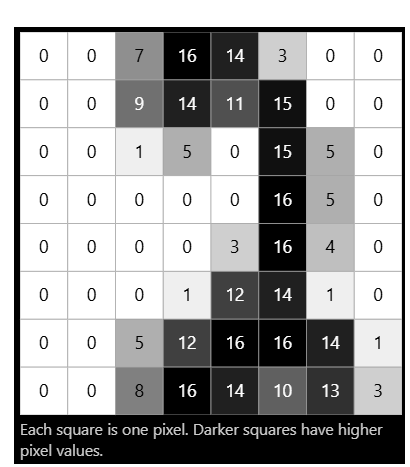

(1797, 65)
Missing values: 0

Images per digit:
target
0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180
Name: count, dtype: int64


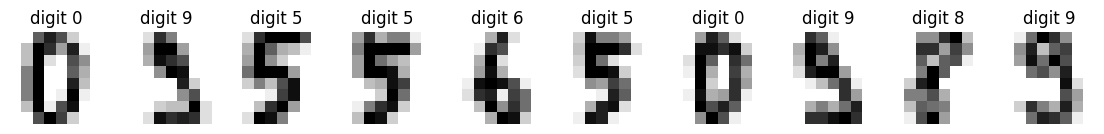

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

print(digits.shape)
print("Missing values:", digits.isna().sum().sum()) #first sum() counts for columns, second for all the dataset
print()
print("Images per digit:")
print(digits['target'].value_counts().sort_index()) # sort_index() displays the digits in numerical order

# show the first 10 images
fig, axes = plt.subplots(1, 10, figsize=(14, 2))

for i, ax in enumerate(axes, start=30):
    # Select image i, remove the target column, and reshape 64 pixels into an 8×8 grid
    # cmap='gray_r' displays 0 as white and 16 as black
    ax.imshow(digits.drop(columns='target').iloc[i].values.reshape(8, 8), cmap='gray_r')
    ax.set_title(f"digit {digits['target'].iloc[i]}")
    ax.axis('off')
plt.show()

## Step 2: Split the data once

We split once and use the **same** training and test sets for every model in this lab, so the comparisons are fair.
`stratify=y` keeps the share of each digit the same in both sets.

In [ ]:
from sklearn.model_selection import train_test_split

X = digits.drop(columns='target')   # the 64 pixel features
y = digits['target']                # the digit

X_train, X_test, y_train, y_test = train_test_split(
    X, y, stratify=y, random_state=0)

print("Training images:", X_train.shape)
print("Test images:", X_test.shape)

Training images: (1347, 64)
Test images: (450, 64)


## Step 3: Baseline, a single decision tree

A tree that may grow as deep as it likes can memorize the training data.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=0)
tree.fit(X_train, y_train)

print("Tree, accuracy on training set:", round(tree.score(X_train, y_train), 3))
print("Tree, accuracy on test set:    ", round(tree.score(X_test, y_test), 3))

Tree, accuracy on training set: 1.0
Tree, accuracy on test set:     0.856


**Question 1.** Is there a gap between the training and the test accuracy? What does that gap tell you?

## Step 4: Your first random forest

A random forest builds many trees. At every split each tree may only look at a random subset of the features (`max_features`), so the trees end up different from each other. The forest then averages the trees' predicted probabilities.

`n_estimators=100` means 100 trees.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(n_estimators=100, random_state=0)
forest.fit(X_train, y_train)

print("Forest, accuracy on training set:", round(forest.score(X_train, y_train), 3))
print("Forest, accuracy on test set:    ", round(forest.score(X_test, y_test), 3))

Forest, accuracy on training set: 1.0
Forest, accuracy on test set:     0.982


**Your turn.** Fit a forest with only `n_estimators=5` and print its training and test accuracy. Is it better or worse than the 100-tree forest?

In [ ]:
# Your code here
from sklearn.ensemble import RandomForestClassifier

forest2 = RandomForestClassifier(n_estimators=5, random_state=0)
forest2.fit(X_train, y_train)

print("Forest, accuracy on training set:", round(forest2.score(X_train, y_train), 3))
print("Forest, accuracy on test set:    ", round(forest2.score(X_test, y_test), 3))

Forest, accuracy on training set: 0.992
Forest, accuracy on test set:     0.913


## Step 5: Look inside the forest

The 100 trees are stored in `forest.estimators_`. First, how good is each tree **on its own**? Then, how does the forest's vote compare?

In [ ]:
#When we access individual trees using forest.estimators_, those trees were trained internally using NumPy-style feature arrays.
#Convert from Pandas DataFrame into a NumPy array to avoid potential warnings about feature names.
X_test_array = X_test.to_numpy()

tree_scores = [t.score(X_test_array, y_test) for t in forest.estimators_]

print("Test accuracy of the first 5 trees:", np.round(tree_scores[:5], 3))
print("Average single tree in the forest: ", round(np.mean(tree_scores), 3))
print("Best single tree in the forest:    ", round(np.max(tree_scores), 3))
print("The whole forest:                  ", round(forest.score(X_test, y_test), 3))



Test accuracy of the first 5 trees: [0.738 0.758 0.809 0.789 0.778]
Average single tree in the forest:  0.764
Best single tree in the forest:     0.82
The whole forest:                   0.982


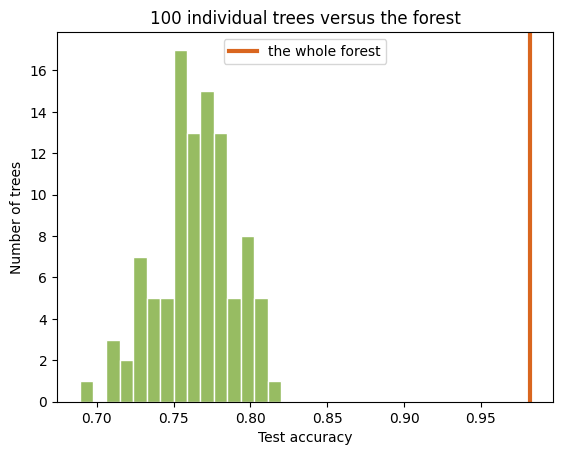

In [ ]:
plt.hist(tree_scores, bins=15, color='#97BC62', edgecolor='white')
plt.axvline(forest.score(X_test, y_test), color='#D9661F', linewidth=3, label='the whole forest')


plt.xlabel('Test accuracy')
plt.ylabel('Number of trees')
plt.title('100 individual trees versus the forest')
plt.legend()
plt.show()

**Question 2.** How does an average tree in the forest compare with the whole forest? Where does the extra accuracy come from?

Now watch the vote for **one** test image. Each tree votes for a digit; the forest combines the votes.

[ 0.  0.  0. 10.  9.  0.  0.  0.  0.  0.  5. 15.  0.  0.  9.  5.  0.  0.
 14. 10.  0.  7. 16.  4.  0.  5. 16.  7.  5. 16.  6.  0.  0. 11. 16. 16.
 16. 14.  0.  0.  0.  3.  4. 11. 16.  8.  0.  0.  0.  0.  0.  7. 16.  2.
  0.  0.  0.  0.  0. 12. 12.  0.  0.  0.]


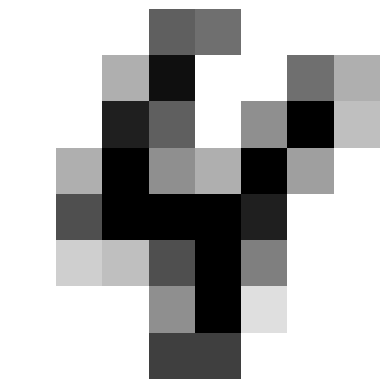

In [ ]:
i = 2  # change this to look at another test image
image = X_test_array[i]
print(image)

plt.imshow(image.reshape(8, 8), cmap='gray_r')
plt.axis('off')
plt.show()

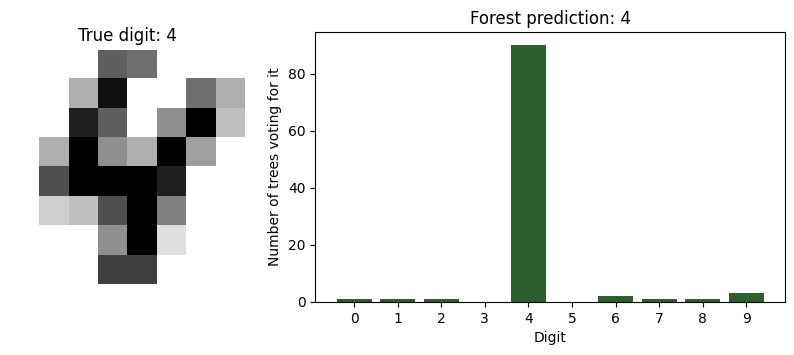

In [ ]:
# each tree predicts a digit (as a number); int() turns it into a whole number
votes = np.array([int(t.predict([image])[0]) for t in forest.estimators_])
vote_counts = np.bincount(votes, minlength=10)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5), gridspec_kw={'width_ratios': [1, 2]})

#print the digit
ax1.imshow(image.reshape(8, 8), cmap='gray_r')
ax1.set_title(f"True digit: {y_test.iloc[i]}")
ax1.axis('off')

#print the votes
ax2.bar(range(10), vote_counts, color='#2C5F2D')
ax2.set_xticks(range(10))
ax2.set_xlabel('Digit')
ax2.set_ylabel('Number of trees voting for it')
ax2.set_title(f"Forest prediction: {forest.predict(X_test.iloc[[i]])[0]}")
plt.show()

**Your turn.** Change `i` to a few other test images. Check the votes each time. Does the forest still get it right?

In [ ]:
# Your code here

## Step 6: How many trees? (`n_estimators`)

A forest is random, so one run can be lucky or unlucky. To get a stable picture, the helper below fits the forest with 5 different random seeds and **averages** the accuracies.

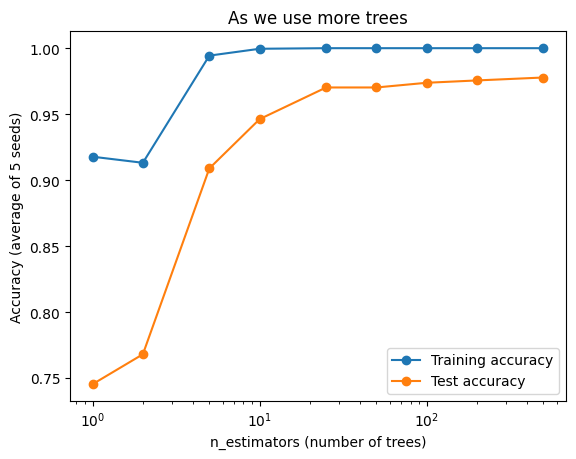

In [ ]:
def forest_accuracy(seeds=range(5), **params): # **params allows us to pass Random Forest settings, such as n_estimators or max_depth
    """Fit a forest once per seed and return the average train and test accuracy."""
    train_acc, test_acc = [], []
    for seed in seeds:
        rf = RandomForestClassifier(random_state=seed, **params)
        rf.fit(X_train, y_train)
        train_acc.append(rf.score(X_train, y_train))
        test_acc.append(rf.score(X_test, y_test))
    return np.mean(train_acc), np.mean(test_acc)

tree_counts = [1, 2, 5, 10, 25, 50, 100, 200, 500]
train_scores, test_scores = [], []
for n in tree_counts:
    tr, te = forest_accuracy(n_estimators=n)
    train_scores.append(tr)
    test_scores.append(te)

plt.plot(tree_counts, train_scores, marker='o', label='Training accuracy')
plt.plot(tree_counts, test_scores, marker='o', label='Test accuracy')
plt.xscale('log')
plt.xlabel('n_estimators (number of trees)')
plt.ylabel('Accuracy (average of 5 seeds)')
plt.title('As we use more trees')
plt.legend()
plt.show()

As we increase the number of trees, training accuracy reaches 100%, but test accuracy also improves and approaches training accuracy. This demonstrates one of the main advantages of random forests: combining many decision trees reduces variance and improves generalization, even when individual trees may overfit their training data.

One additional point: Adding more trees does not necessarily make each individual tree less overfit. Instead, averaging their predictions reduces the impact of individual trees' errors.

**Side note:** A docstring is a description written inside triple quotation marks (`""" """`) that explains what a function does. Unlike a regular comment (`#`), a docstring is stored by Python and can be accessed using `help()` to understand how the function works.

In [ ]:
help(forest_accuracy)

Help on function forest_accuracy in module __main__:

forest_accuracy(seeds=range(0, 5), **params)
    Fit a forest once per seed and return the average train and test accuracy.



**Question 3.** What happens to the test accuracy as you add trees? Does it ever get clearly worse with more trees? What is the price of adding more trees?

## Step 7: How random should each tree be? (`max_features`)

The data has 64 features. `max_features` is how many features each split may look at. With `max_features=64` every split sees all pixels, so there is **no feature randomness** at all.

The classification default is the square root of the number of features: the square root of 64 is 8.

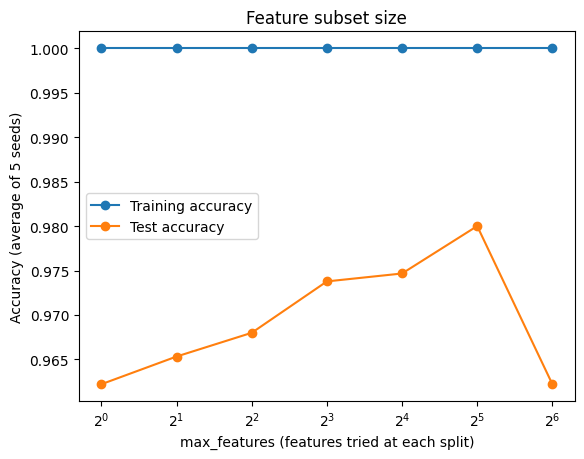

,max_features,test accuracy
0,1,0.962
1,2,0.965
2,4,0.968
3,8,0.974
4,16,0.975
5,32,0.980
6,64,0.962


In [ ]:
feature_counts = [1, 2, 4, 8, 16, 32, 64]

train_scores, test_scores = [], []
for m in feature_counts:
    tr, te = forest_accuracy(n_estimators=100, max_features=m) # remember forest_accuracy ranges over 5 seeds
    train_scores.append(tr)
    test_scores.append(te)

plt.plot(feature_counts, train_scores, marker='o', label='Training accuracy')
plt.plot(feature_counts, test_scores, marker='o', label='Test accuracy')
plt.xscale('log', base=2)
plt.xlabel('max_features (features tried at each split)')
plt.ylabel('Accuracy (average of 5 seeds)')
plt.title('Feature subset size')
plt.legend()
plt.show()

pd.DataFrame({'max_features': feature_counts, 'test accuracy': np.round(test_scores, 3)})

**Question 4.** Which `max_features` values work best? What happens with `max_features=64`, and why does that make the trees more alike? (Hint: think about the **strongest** pixels.)

Key takeaway: Random forests work well partly because their trees are different. Limiting max_features encourages diversity, which can reduce variance and improve generalization. However, using too few features can also hurt accuracy.

## Step 8: How big is each tree? (`max_depth`)

`max_depth` limits how deep each tree can grow. `None` means no limit.

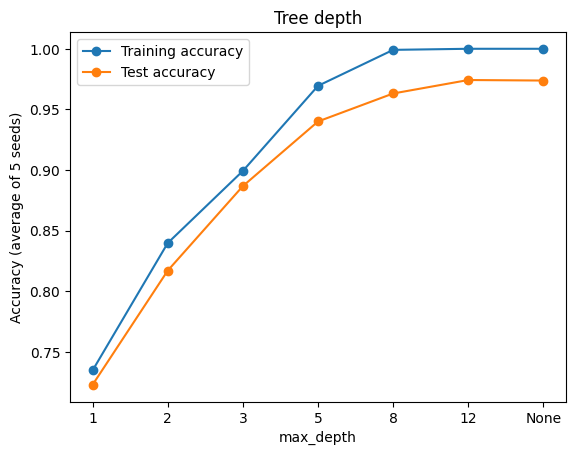

In [ ]:
depths = [1, 2, 3, 5, 8, 12, None]
train_scores, test_scores = [], []
for d in depths:
    tr, te = forest_accuracy(n_estimators=100, max_depth=d)
    train_scores.append(tr)
    test_scores.append(te)

labels = [str(d) for d in depths]
plt.plot(labels, train_scores, marker='o', label='Training accuracy')
plt.plot(labels, test_scores, marker='o', label='Test accuracy')
plt.xlabel('max_depth')
plt.ylabel('Accuracy (average of 5 seeds)')
plt.title('Tree depth')
plt.legend()
plt.show()

**Question 5.** Very shallow trees are weak. How deep do the trees need to be before the forest stops improving?

## Step 9: Which pixels matter? (feature importance)

Because each pixel is a feature, we can draw the importances **as an image**.

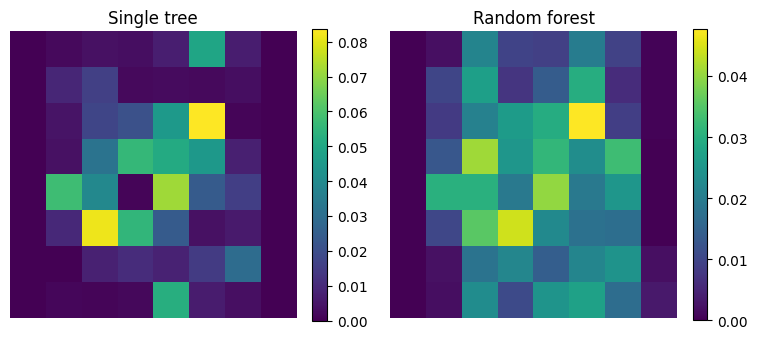

In [ ]:
big_forest = RandomForestClassifier(n_estimators=500, random_state=0)
big_forest.fit(X_train, y_train)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4))
for ax, imp, title in [(ax1, tree.feature_importances_, 'Single tree'),
                       (ax2, big_forest.feature_importances_, 'Random forest')]:
    im = ax.imshow(imp.reshape(8, 8), cmap='viridis')
    ax.set_title(title)
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.show()


top10_share function:

1. Sorts all 64 feature importance values from smallest to largest.
2. [::-1] reverses the order (largest first).
3. [:10] selects the 10 most important pixels.
4. .sum() adds their importance values.

Since the importance values add up to 1, the result represents the percentage of total importance attributed to the top 10 pixels.

In [ ]:
def top10_share(importances):
    # share of the total importance held by the 10 most important pixels
    return np.sort(importances)[::-1][:10].sum()

print("Share of total importance held by the 10 most important pixels:")
print("  single tree:  ", round(top10_share(tree.feature_importances_), 2))
print("  random forest:", round(top10_share(big_forest.feature_importances_), 2))

Share of total importance held by the 10 most important pixels:
  single tree:   0.6
  random forest: 0.36


**Question 6.** Does the single tree spread its importance over many pixels or only a few? What about the forest? Remember: importance shows which pixels the model *used*, not why a digit looks the way it does.

A single decision tree concentrates much of its decision-making on a few important pixels, while a random forest distributes importance across more pixels. In our example, the top 10 pixels account for 60% of the importance in the single tree but only 36% in the random forest. This illustrates how combining many trees allows the forest to use a wider variety of features rather than relying heavily on a few.

One additional technical point: The heatmaps have different color scales (approximately 0–0.08 versus 0–0.05). Therefore, the same color in both graphs does not represent the same importance value. The numerical results of 60% and 36% provide a clearer comparison of importance concentration.

## Step 10: Compare with gradient boosting

Boosting builds shallow trees one after another, each correcting the mistakes of the previous ones. We fit it on the same split. This step takes a few seconds.

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

models = {
    'Decision tree': DecisionTreeClassifier(random_state=0),
    'Random forest (100 trees)': RandomForestClassifier(n_estimators=100, random_state=0),
    'Gradient boosting (defaults)': GradientBoostingClassifier(random_state=0),
}

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    rows.append({
        'Model': name,
        'Train accuracy': round(model.score(X_train, y_train), 3),
        'Test accuracy': round(model.score(X_test, y_test), 3),
    })

pd.DataFrame(rows)

,Model,Train accuracy,Test accuracy
0,Decision tree,1.0,0.856
1,Random forest (100 trees),1.0,0.982
2,Gradient boosting (defaults),1.0,0.964


**Question 7.** Which model has the best test accuracy? Which models reach 1.000 on the training set? In practice, which would you try first and why?

## Wrap-up

Write three or four sentences in your own words:
- Why does a forest generalize better than a single tree?
- What makes the trees in a forest different from each other?
- Which parameter mattered most in this lab?

